In [17]:
from complexeva.sequence import hfd

In [18]:
import numpy as np

def fbm(hurst, timeseries_len):
        """
        Generate fractional Brownian motion (fBm) time series.

        This method uses the spectral synthesis method to generate a fBm time series
        with a specified Hurst exponent.

        Parameters:
        -----------
        hurst : float
            The Hurst exponent, a value between 0 and 1 that characterizes
            the fractal properties of the time series.

        Returns:
        --------
        numpy.ndarray
            A 1D array representing the generated fBm time series.

        Notes:
        ------
        - The length of the generated time series is determined by self.timeseries_len.
        - This method uses the Fourier filtering method to generate fBm.
        - The first frequency component is set to a small non-zero value (1e-6) to avoid division by zero.
        """

        n = timeseries_len
        f = np.fft.fftfreq(n)
        f[0] = 1e-6  # avoid division by zero
        psd = np.abs(f) ** (-2 * hurst - 1)
        gaussian = np.random.randn(n) + 1j * np.random.randn(n)
        fBm = np.fft.ifft(gaussian * np.sqrt(psd)).real
        return fBm

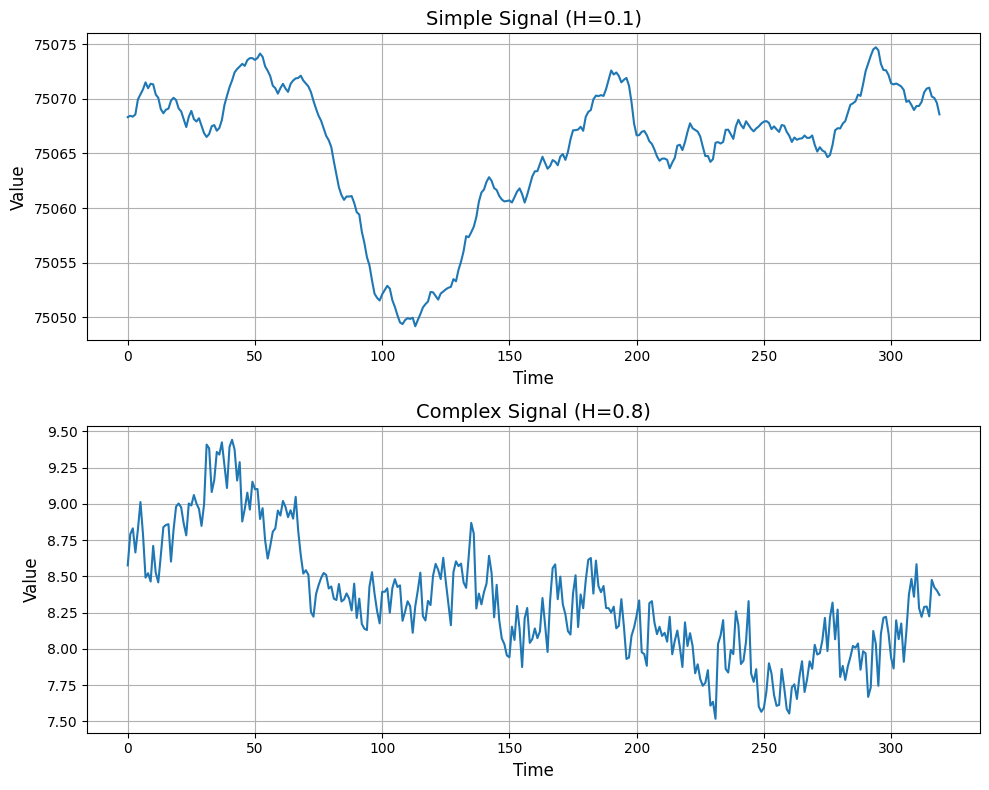

In [19]:
signal_1_simple = fbm(0.8, 320)
signal_2_complex = fbm(0.1, 320)

import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(signal_1_simple)
ax1.set_title("Simple Signal (H=0.1)", fontsize=14)
ax1.set_xlabel("Time", fontsize=12)
ax1.set_ylabel("Value", fontsize=12)
ax1.grid(True)

ax2.plot(signal_2_complex)
ax2.set_title("Complex Signal (H=0.8)", fontsize=14)
ax2.set_xlabel("Time", fontsize=12)
ax2.set_ylabel("Value", fontsize=12)
ax2.grid(True)

plt.tight_layout()
plt.show()


HFD of signal 1 (simple) (predicted): 0.2731080135302147
HFD of signal 2 (complex) (predictor): 0.7987772315284489
HFD of signal predicted: 0.7987772315284675


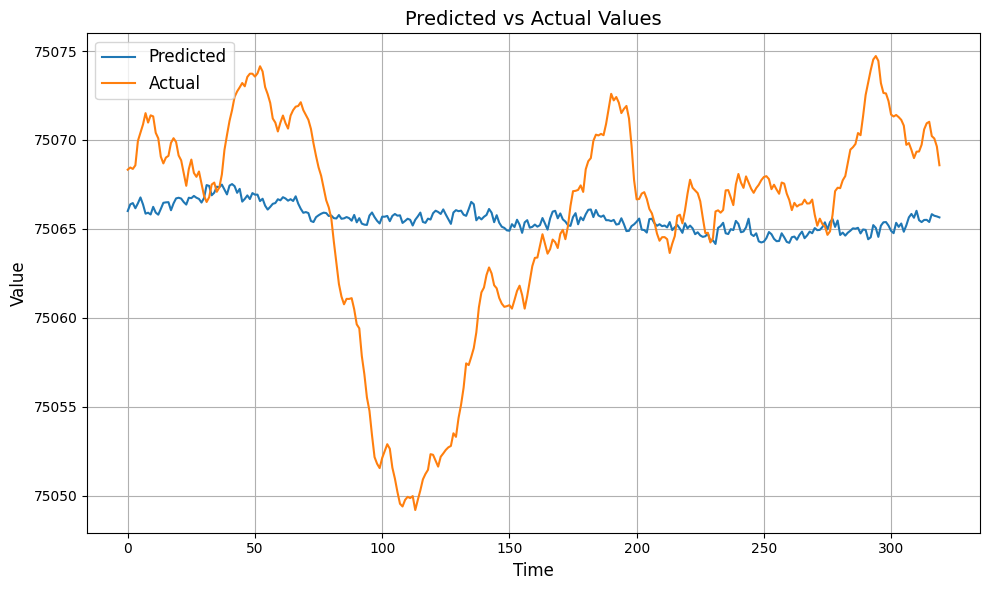

In [20]:
from sklearn.linear_model import LinearRegression

# Reshape the signals for sklearn
X = signal_2_complex.reshape(-1, 1)  # Independent variable
y = signal_1_simple  # Dependent variable

# Create and fit the model
model = LinearRegression()
model.fit(X, y)

# Make predictions
y_pred = model.predict(X)

from complexeva.sequence import hfd

hfd_signal_1 = hfd(signal_1_simple)
hfd_signal_2 = hfd(signal_2_complex)
hfd_signal_predicted = hfd(y_pred)

print(f"HFD of signal 1 (simple) (predicted): {hfd_signal_1}")
print(f"HFD of signal 2 (complex) (predictor): {hfd_signal_2}")
print(f"HFD of signal predicted: {hfd_signal_predicted}")

# Plot the predictions
plt.figure(figsize=(10, 6))
plt.plot(y_pred, label='Predicted')
plt.plot(y, label='Actual')
plt.title('Predicted vs Actual Values', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.grid(True)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


HFD of signal 1 (simple) (predictor): 0.2731080135302147
HFD of signal 2 (complex) (predicted): 0.7987772315284489
HFD of signal predicted: 0.27310801353011743


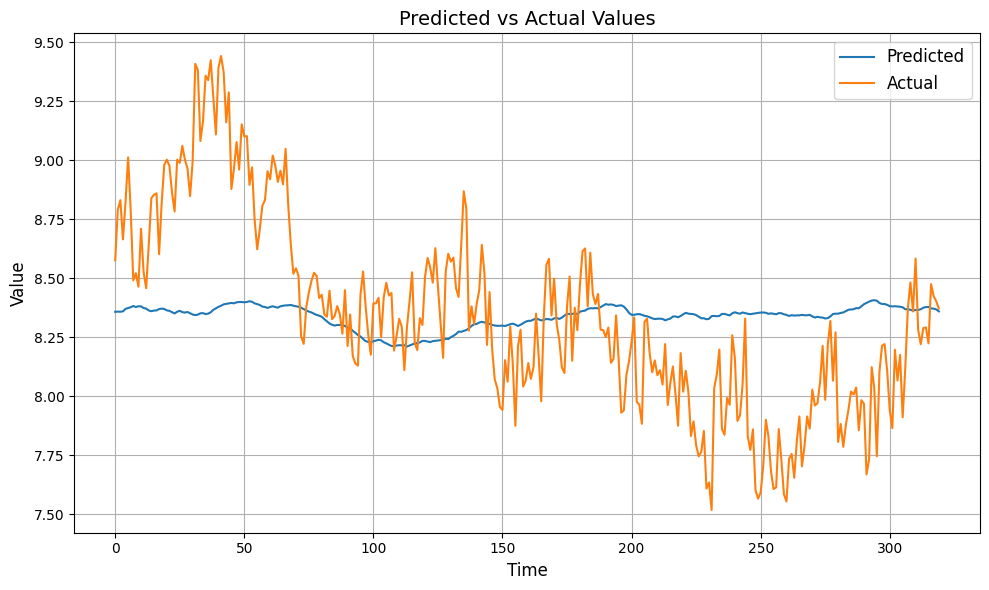

In [21]:
from sklearn.linear_model import LinearRegression

# Reshape the signals for sklearn
X = signal_1_simple.reshape(-1, 1)  # Dependent variable
y = signal_2_complex  # Independent variable

# Create and fit the model
model = LinearRegression()
model.fit(X, y)

# Make predictions
y_pred = model.predict(X)

from complexeva.sequence import hfd

hfd_signal_1 = hfd(signal_1_simple)
hfd_signal_2 = hfd(signal_2_complex)
hfd_signal_predicted = hfd(y_pred)

print(f"HFD of signal 1 (simple) (predictor): {hfd_signal_1}")
print(f"HFD of signal 2 (complex) (predicted): {hfd_signal_2}")
print(f"HFD of signal predicted: {hfd_signal_predicted}")

# Plot the predictions
plt.figure(figsize=(10, 6))
plt.plot(y_pred, label='Predicted')
plt.plot(y, label='Actual')
plt.title('Predicted vs Actual Values', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.grid(True)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


